In [1]:
words = open('names.txt', 'r').read().splitlines()
words[:10]

['emma',
 'olivia',
 'ava',
 'isabella',
 'sophia',
 'charlotte',
 'mia',
 'amelia',
 'harper',
 'evelyn']

In [2]:
b = {}
for w in words:
  chs = ['<S>'] + list(w) + ['<E>']
  for ch1, ch2 in zip(chs, chs[1:]):
    bigram = (ch1, ch2)
    b[bigram] = b.get(bigram, 0) + 1

In [3]:
sorted(b.items(), key = lambda kv: -kv[1])

[(('n', '<E>'), 6763),
 (('a', '<E>'), 6640),
 (('a', 'n'), 5438),
 (('<S>', 'a'), 4410),
 (('e', '<E>'), 3983),
 (('a', 'r'), 3264),
 (('e', 'l'), 3248),
 (('r', 'i'), 3033),
 (('n', 'a'), 2977),
 (('<S>', 'k'), 2963),
 (('l', 'e'), 2921),
 (('e', 'n'), 2675),
 (('l', 'a'), 2623),
 (('m', 'a'), 2590),
 (('<S>', 'm'), 2538),
 (('a', 'l'), 2528),
 (('i', '<E>'), 2489),
 (('l', 'i'), 2480),
 (('i', 'a'), 2445),
 (('<S>', 'j'), 2422),
 (('o', 'n'), 2411),
 (('h', '<E>'), 2409),
 (('r', 'a'), 2356),
 (('a', 'h'), 2332),
 (('h', 'a'), 2244),
 (('y', 'a'), 2143),
 (('i', 'n'), 2126),
 (('<S>', 's'), 2055),
 (('a', 'y'), 2050),
 (('y', '<E>'), 2007),
 (('e', 'r'), 1958),
 (('n', 'n'), 1906),
 (('y', 'n'), 1826),
 (('k', 'a'), 1731),
 (('n', 'i'), 1725),
 (('r', 'e'), 1697),
 (('<S>', 'd'), 1690),
 (('i', 'e'), 1653),
 (('a', 'i'), 1650),
 (('<S>', 'r'), 1639),
 (('a', 'm'), 1634),
 (('l', 'y'), 1588),
 (('<S>', 'l'), 1572),
 (('<S>', 'c'), 1542),
 (('<S>', 'e'), 1531),
 (('j', 'a'), 1473),
 (

In [4]:
import torch

In [5]:
N = torch.zeros((27, 27), dtype=torch.int32)

In [6]:

chars = sorted(list(set(''.join(words))))
stoi = {s:i+1 for i,s in enumerate(chars)}
stoi['.'] = 0
itos = {i:s for s,i in stoi.items()}

In [13]:
for w in words:
  chs = ['.'] + list(w) + ['.']
  for ch1, ch2 in zip(chs, chs[1:]):
    ix1 = stoi[ch1]
    ix2 = stoi[ch2]
    N[ix1, ix2] += 1

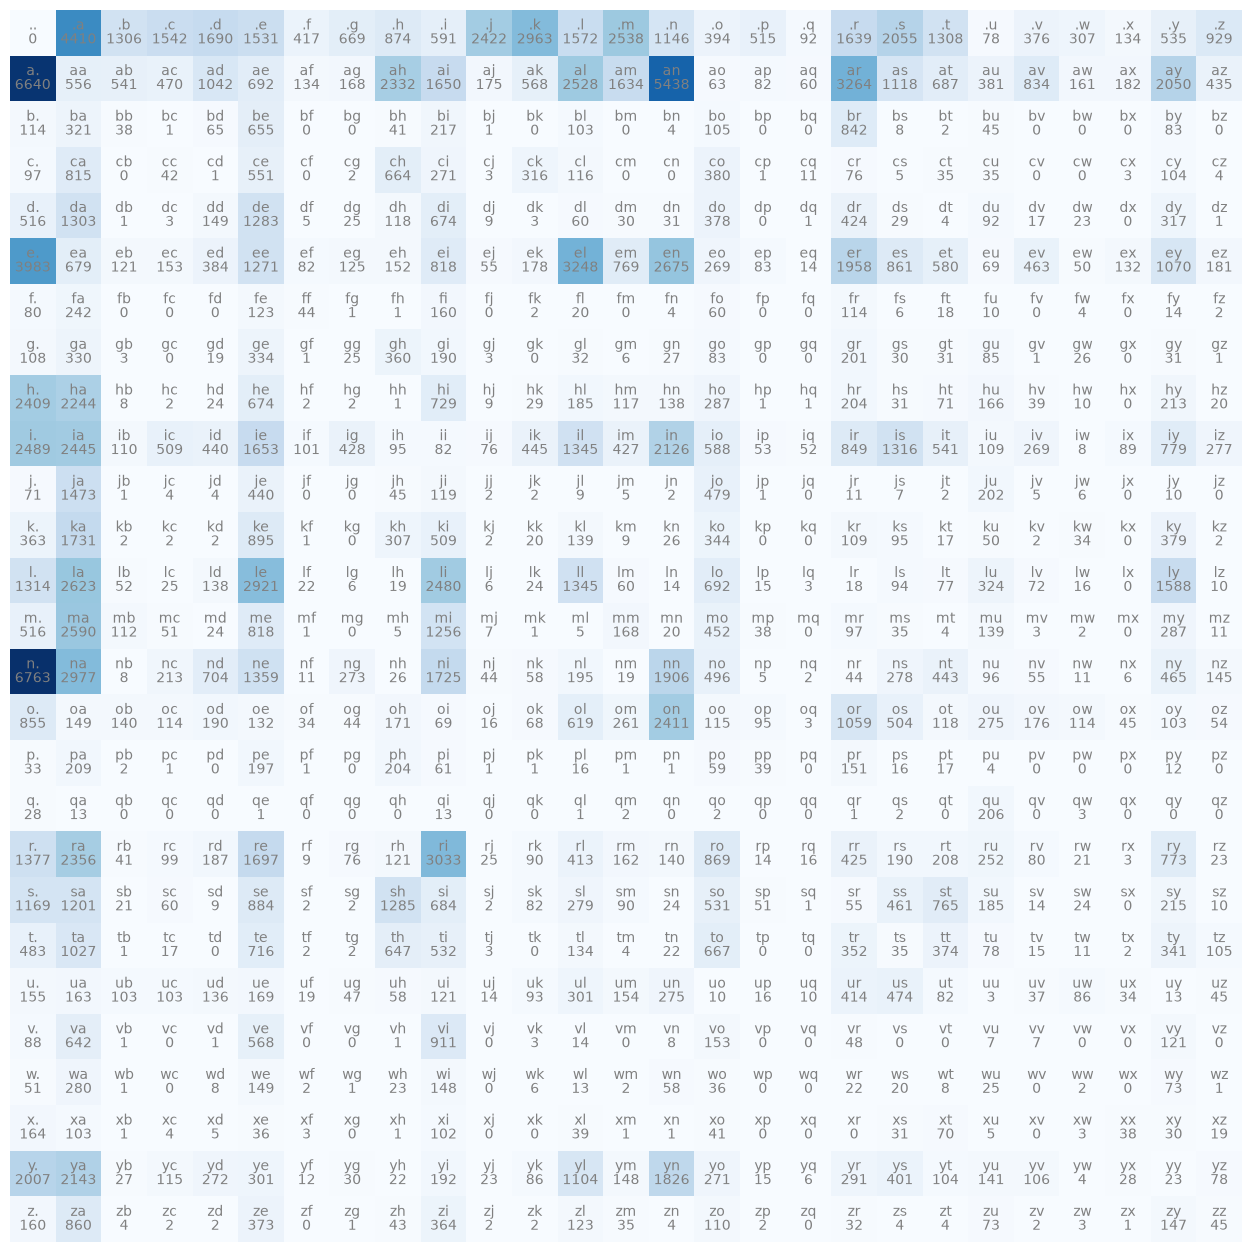

In [14]:

import matplotlib.pyplot as plt
%matplotlib inline

plt.figure(figsize=(16,16))
plt.imshow(N, cmap='Blues')
for i in range(27):
    for j in range(27):
        chstr = itos[i] + itos[j]
        plt.text(j, i, chstr, ha="center", va="bottom", color='gray')
        plt.text(j, i, N[i, j].item(), ha="center", va="top", color='gray')
plt.axis('off');


In [15]:
N[0]

tensor([   0, 4410, 1306, 1542, 1690, 1531,  417,  669,  874,  591, 2422, 2963,
        1572, 2538, 1146,  394,  515,   92, 1639, 2055, 1308,   78,  376,  307,
         134,  535,  929], dtype=torch.int32)

In [16]:
p = N[0].float()
p = p / p.sum()
p

tensor([0.0000, 0.1377, 0.0408, 0.0481, 0.0528, 0.0478, 0.0130, 0.0209, 0.0273,
        0.0184, 0.0756, 0.0925, 0.0491, 0.0792, 0.0358, 0.0123, 0.0161, 0.0029,
        0.0512, 0.0642, 0.0408, 0.0024, 0.0117, 0.0096, 0.0042, 0.0167, 0.0290])

In [17]:

g = torch.Generator().manual_seed(2147483647)
ix = torch.multinomial(p, num_samples=1, replacement=True, generator=g).item()
itos[ix]

'c'

In [18]:

g = torch.Generator().manual_seed(2147483647)
p = torch.rand(3, generator=g)
p = p / p.sum()
p

tensor([0.6064, 0.3033, 0.0903])

In [19]:
torch.multinomial(p, num_samples=100, replacement=True, generator=g)

tensor([1, 1, 2, 0, 0, 2, 1, 1, 0, 0, 0, 1, 1, 0, 0, 1, 1, 0, 0, 1, 0, 2, 0, 0,
        1, 0, 0, 1, 0, 0, 0, 1, 1, 1, 0, 1, 1, 0, 0, 1, 1, 1, 0, 1, 1, 0, 1, 1,
        0, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0,
        0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 2, 0, 0, 0, 0, 0, 0, 1, 0, 0, 2, 0, 1, 0,
        0, 1, 1, 1])

In [24]:
P = (N+1).float()
P /= P.sum(1, keepdims=True) #27x27, 27x1 , broadcasting
g = torch.Generator().manual_seed(2147483647)

for i in range(5):
  
  out = []
  ix = 0
  while True:
    p = P[ix]
    ix = torch.multinomial(p, num_samples=1, replacement=True, generator=g).item()
    out.append(itos[ix])
    if ix == 0:
      break
  print(''.join(out))

cexze.
momasurailezitynn.
konimittain.
llayn.
ka.


## The loss function


In [34]:
log_likelyhood=0
n=0
for w in words[:3]:
  chs = ['.'] + list(w) + ['.']
  for ch1, ch2 in zip(chs, chs[1:]):
    ix1 = stoi[ch1]
    ix2 = stoi[ch2]
    prob = P [ix1,ix2]
    logprob=torch.log(prob)
    log_likelyhood+=logprob
    n+=1
    # print(f'{ch1}{ch2}: {prob:.4f} {logprob:.4f}')
    #expecting 4%, if higher its meaningful
nll=-log_likelyhood
print(f'{nll=}')
anll=nll/n
print(f'{anll=}')

nll=tensor(38.8086)
anll=tensor(2.4255)


The likelyhood is the product of all of these probabilities, it should be high

The log likelyhood is more used

GOAL ; Maximize likelyhood  with respect to the model parameters (the probabilities)

Change params to maximize likelyhood (log likelyhood)


In [96]:
# create the set of bigras (x,y)

xs,ys = [], []

for w in words[:1]:
  chs = ['.'] + list(w) + ['.']
  for ch1, ch2 in zip(chs, chs[1:]):
    ix1 = stoi[ch1]
    ix2 = stoi[ch2]
    xs.append(ix1)
    ys.append(ix2)
xs=torch.tensor(xs)
ys=torch.tensor(ys)

#torch.Tensor is also allowed


In [97]:
xs

tensor([ 0,  5, 13, 13,  1])

In [61]:
ys

tensor([ 5, 13, 13,  1,  0])

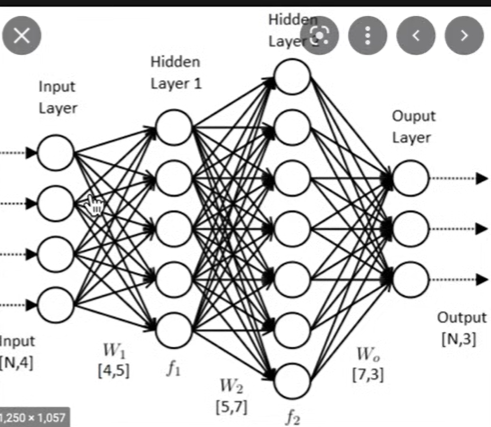

One hot encoding

In [98]:
import torch.nn.functional as F
xenc = F.one_hot(xs, num_classes=27).float()
xenc

tensor([[1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
         0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
         0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0.,
         0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0.,
         0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
         0., 0., 0., 0., 0., 0., 0., 0., 0.]])

In [99]:
xenc.shape

torch.Size([5, 27])

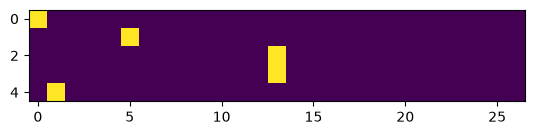

In [100]:
plt.imshow(xenc)

In [101]:
xenc.dtype #floats can feed into nns


torch.float32

In [102]:

W = torch.randn((27, 27), generator = g, requires_grad = True) # important!
xenc @ W

tensor([[ 0.3533, -0.6542, -0.5777, -0.6484, -1.0169,  0.2794,  0.8459,  0.4698,
          0.2449, -0.1773, -1.1247, -0.2146,  0.6387, -0.3248, -0.4847, -1.9747,
          1.8418,  0.0257, -0.5090,  1.2560,  0.1353, -0.8001, -0.5752, -0.6114,
         -1.5635, -0.3476, -0.2105],
        [ 0.5928, -0.3375, -0.9322, -0.5819,  0.7788, -1.4592,  1.6741, -1.9215,
          0.3348,  2.3770, -0.0076, -1.1906, -0.7821,  0.7355, -2.2746, -1.7141,
         -0.3024,  0.3871, -1.6364,  0.2034, -0.4174,  0.8958, -1.3596, -1.6637,
          0.3973, -1.7495, -0.9868],
        [-1.2249, -1.0487, -1.4704, -0.6206,  1.7169, -0.8771,  1.1558, -1.5436,
         -0.7944, -0.0049, -0.4989,  1.0486, -1.0589,  0.6123, -2.7347, -1.6719,
         -1.5645,  0.5486, -0.7775, -0.1697, -0.3959,  2.4176, -0.4238, -0.5927,
         -2.7371, -0.3176, -0.0529],
        [-1.2249, -1.0487, -1.4704, -0.6206,  1.7169, -0.8771,  1.1558, -1.5436,
         -0.7944, -0.0049, -0.4989,  1.0486, -1.0589,  0.6123, -2.7347, -1.6719

In [103]:

# forward pass
xenc = F.one_hot(xs, num_classes=27).float() # input to the network: one-hot encoding
logits = xenc @ W # predict log-counts
counts = logits.exp() # counts, equivalent to N
probs = counts / counts.sum(1, keepdims=True) # probabilities for next character
loss = -probs[torch.arange(5), ys].log().mean()
loss

tensor(3.3611, grad_fn=<NegBackward0>)

In [104]:
#backward pass
W.grad = None # set grad to 0
loss.backward()


In [81]:
W.shape


torch.Size([27, 27])

In [105]:
W.grad

tensor([[ 0.0091,  0.0033,  0.0036,  0.0034,  0.0023, -0.1915,  0.0150,  0.0103,
          0.0082,  0.0054,  0.0021,  0.0052,  0.0122,  0.0046,  0.0040,  0.0009,
          0.0405,  0.0066,  0.0039,  0.0226,  0.0074,  0.0029,  0.0036,  0.0035,
          0.0013,  0.0045,  0.0052],
        [-0.1915,  0.0008,  0.0050,  0.0045,  0.0010,  0.0091,  0.0055,  0.0106,
          0.0031,  0.0004,  0.0270,  0.0040,  0.0189,  0.0014,  0.0032,  0.0424,
          0.0029,  0.0015,  0.0045,  0.0018,  0.0029,  0.0081,  0.0018,  0.0035,
          0.0013,  0.0154,  0.0110],
        [ 0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,
          0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,
          0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,
          0.0000,  0.0000,  0.0000],
        [ 0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,
          0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000

In [106]:
# update the weights
W.data += -0.1 * W.grad
print(loss.item())

3.3610641956329346


In [ ]:
# optimize

# create the dataset
xs, ys = [], []
for w in words:
  chs = ['.'] + list(w) + ['.']
  for ch1, ch2 in zip(chs, chs[1:]):
    ix1 = stoi[ch1]
    ix2 = stoi[ch2]
    xs.append(ix1)
    ys.append(ix2)
xs = torch.tensor(xs)
ys = torch.tensor(ys)
num = xs.nelement()
print('number of examples: ', num)

# initialize the 'network'
g = torch.Generator().manual_seed(2147483647)
W = torch.randn((27, 27), generator=g, requires_grad=True)

In [107]:
# gradient descent
for k in range(1):
  
  # forward pass
  xenc = F.one_hot(xs, num_classes=27).float() # input to the network: one-hot encoding
  logits = xenc @ W # predict log-counts
  counts = logits.exp() # counts, equivalent to N
  probs = counts / counts.sum(1, keepdims=True) # probabilities for next character
  loss = -probs[torch.arange(num), ys].log().mean() + 0.01*(W**2).mean()
  print(loss.item())
  
  # backward pass
  W.grad = None # set to zero the gradient
  loss.backward()
  
  # update
  W.data += -50 * W.grad

NameError: name 'num' is not defined

In [108]:
# finally, sample from the 'neural net' model
g = torch.Generator().manual_seed(2147483647)

for i in range(5):
  
  out = []
  ix = 0
  while True:
    
    # ----------
    # BEFORE:
    #p = P[ix]
    # ----------
    # NOW:
    xenc = F.one_hot(torch.tensor([ix]), num_classes=27).float()
    logits = xenc @ W # predict log-counts
    counts = logits.exp() # counts, equivalent to N
    p = counts / counts.sum(1, keepdims=True) # probabilities for next character
    # ----------
    
    ix = torch.multinomial(p, num_samples=1, replacement=True, generator=g).item()
    out.append(itos[ix])
    if ix == 0:
      break
  print(''.join(out))

gexbmdzomukurajlqznzyhwlllzisjlnznzjlgfvkznhvmu.
sfazvpbbjtbsryiotzjmudzjrqhwxugkwgtedagkkldmkmmsidzuetkqvnznzzqtbspmhwlivchvtallzovqhsfrxbbnznlbpyiwxvqtyjwlpzdwchsfznmkdbsf.
freit.
gccksjmqzabsvqth.
qhyjlqefrbmfrlmdfahsrjecvxmvpooqzmudfvjzoobnzydox.
